# Step 10 — 2D Poisson Equation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step10_poisson_2d.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

The [Poisson equation](https://en.wikipedia.org/wiki/Poisson%27s_equation) adds a source term to the Laplace equation:

$$
\nabla^2 p = b
$$

**Physics:** The Poisson equation is the **pressure equation** in incompressible fluid dynamics. After discretising the Navier–Stokes momentum equations, we must solve a Poisson equation at every time step to enforce the divergence-free constraint. Mastering this solver is a prerequisite for Steps 12 and 13.

**What you will learn:**

1. How to solve the Poisson equation with three boundary-condition types
2. The connection between BC type and spectral method (DST / DCT / FFT)
3. How the solver converges as the grid is refined ($O(\Delta x^2)$)
4. Comparative wall-clock times for different BC types

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$, $y$ are the spatial coordinates (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x]$, $y \in [0, L_y]$ | spatial coordinates | $\mathbb{R}$ |
| $L_x$, $L_y$ | domain lengths, both $1$ here | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior cells in $x$ and in $y$ | count |
| $\Delta x$, $\Delta y$ | grid spacings | $\mathbb{R}_{>0}$ |
| $p(x, y)$ | the solved field (the pressure) | $\mathbb{R}$ |
| $b(x, y)$ | the source, the right-hand side | $\mathbb{R}$ |
| $p^\text{exact}(x, y)$ | the known solution of each test problem | $\mathbb{R}$ |
| $p_{j,i}$, $b_{j,i}$ | the fields in the cell of row $j$ and column $i$; the arrays with ghosts have $N_{\Omega_x,y} + 2$ rows and $N_{\Omega_x,x} + 2$ columns | $\mathbb{R}$ |
| $e_{j,i} = p_{j,i} - p^\text{exact}_{j,i}$ | pointwise error | $\mathbb{R}$ |
| $e_\text{rms}$ | root-mean-square error over the interior cells, reported as the "L2 error" | $\mathbb{R}_{\ge 0}$ |
| $\mathbf{n}$ | outward unit normal of a wall | $\mathbb{R}^2$ |
| $\omega(x, y)$, $\psi(x, y)$ | vorticity and streamfunction, in the vortex-pair section | $\mathbb{R}$ |
| $u(x, y)$, $v(x, y)$ | velocity components, in the same section | $\mathbb{R}$ |

## Grid layout and boundary conditions

The solved field $p$ lives at the T-points of [](#fig-cgrid-positions). The spectral solver operates on **interior cells** only. The boundary condition type determines which spectral transform is used.

Three BC types correspond to three spectral transforms:

| BC type | Transform | Ghost condition |
| --- | --- | --- |
| Dirichlet ($p = 0$) | DST | Antisymmetric |
| Neumann ($\nabla p \cdot \mathbf{n} = 0$) | DCT | Symmetric |
| Periodic | FFT | Wrap-around |

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Dirichlet BCs (DST solver)

Homogeneous Dirichlet: $p = 0$ on all walls.

Test problem:

$$
p^\text{exact}(x, y) = \sin(\pi x) \sin(\pi y)
$$

$$
b(x, y) = -2 \pi^2 \sin(\pi x) \sin(\pi y)
$$

In [4]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# N_Ωx,y, N_Ωx,x interior; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

interior = (slice(1, -1), slice(1, -1))


def solve_dirichlet(num_x: int, num_y: int) -> tuple[float, float]:
    """Solve the Dirichlet test problem and return (L2 error, time)."""
    # today (sesmax_core)
    solver = sxt.PoissonSolver2D.create(
        nx=num_x, ny=num_y, Lx=1.0, Ly=1.0, bc="dirichlet"
    )

    # xᵢ = i Δx
    x_index = jnp.arange(solver.grid.Nx)  # → (N_Ωx,x + 2,)
    x_position = x_index * solver.grid.dx  # → (N_Ωx,x + 2,)
    # yⱼ = j Δy
    y_index = jnp.arange(solver.grid.Ny)  # → (N_Ωx,y + 2,)
    y_position = y_index * solver.grid.dy  # → (N_Ωx,y + 2,)
    x_mesh, y_mesh = jnp.meshgrid(x_position, y_position)  # → G

    # sin(π x) sin(π y)
    sine_x = jnp.sin(jnp.pi * x_mesh)  # → G
    sine_y = jnp.sin(jnp.pi * y_mesh)  # → G
    exact = sine_x * sine_y  # → G
    # b = −2π² sin(π x) sin(π y)
    source = -2.0 * jnp.pi**2 * exact  # → G

    # the first call compiles; time the second
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    jax.block_until_ready(solution)
    start_time = time.perf_counter()
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    jax.block_until_ready(solution)
    elapsed = time.perf_counter() - start_time

    # eⱼᵢ = pⱼᵢ − pⱼᵢᵉˣᵃᶜᵗ
    error = solution[interior] - exact[interior]  # → N_Ωx,y × N_Ωx,x
    # e_rms = (mean eⱼᵢ²)^½
    squared_error = error**2  # → N_Ωx,y × N_Ωx,x
    mean_squared_error = jnp.mean(squared_error)  # → ()
    rms_error = float(jnp.sqrt(mean_squared_error))
    return rms_error, elapsed


dirichlet_cells = 64
dirichlet_error, dirichlet_time = solve_dirichlet(dirichlet_cells, dirichlet_cells)
print(
    f"Dirichlet {dirichlet_cells}x{dirichlet_cells}: "
    f"L2 error = {dirichlet_error:.6e}, time = {dirichlet_time:.4f}s"
)

Dirichlet 64x64: L2 error = 1.003862e-04, time = 0.0088s


Visualise the Dirichlet solution:

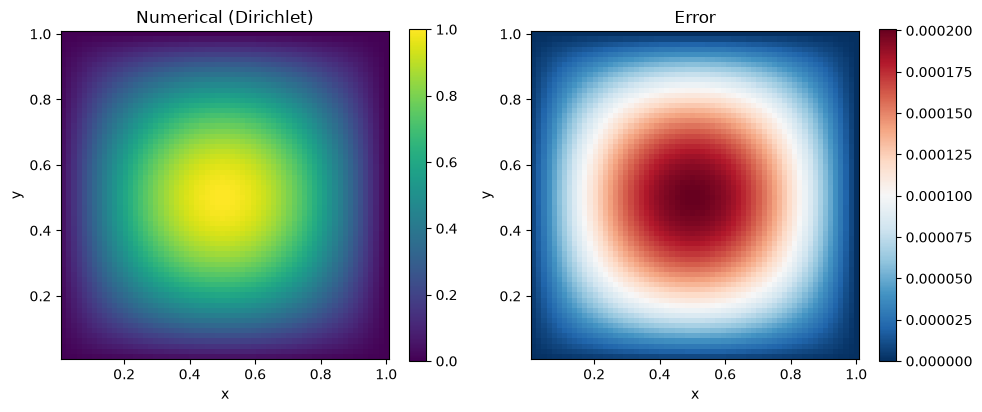

In [5]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# N_Ωx,y, N_Ωx,x interior; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# today (sesmax_core)
dirichlet_solver = sxt.PoissonSolver2D.create(
    nx=64, ny=64, Lx=1.0, Ly=1.0, bc="dirichlet"
)

# xᵢ = i Δx
x_index = jnp.arange(dirichlet_solver.grid.Nx)  # → (N_Ωx,x + 2,)
x_position = x_index * dirichlet_solver.grid.dx  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_index = jnp.arange(dirichlet_solver.grid.Ny)  # → (N_Ωx,y + 2,)
y_position = y_index * dirichlet_solver.grid.dy  # → (N_Ωx,y + 2,)
x_mesh, y_mesh = jnp.meshgrid(x_position, y_position)  # → G

# sin(π x) sin(π y)
sine_x = jnp.sin(jnp.pi * x_mesh)  # → G
sine_y = jnp.sin(jnp.pi * y_mesh)  # → G
# b = −2π² sin(π x) sin(π y)
dirichlet_source = -2.0 * jnp.pi**2 * sine_x * sine_y  # → G
# today (sesmax_core)
dirichlet_solution = dirichlet_solver.solve(dirichlet_source)  # → G
# pᵉˣᵃᶜᵗ = sin(π x) sin(π y)
dirichlet_exact = sine_x * sine_y  # → G
# eⱼᵢ = pⱼᵢ − pⱼᵢᵉˣᵃᶜᵗ
dirichlet_difference = dirichlet_solution - dirichlet_exact  # → G

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].pcolormesh(
    x_mesh[interior], y_mesh[interior], dirichlet_solution[interior], shading="auto"
)
axes[0].set_title("Numerical (Dirichlet)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_aspect("equal")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].pcolormesh(
    x_mesh[interior],
    y_mesh[interior],
    dirichlet_difference[interior],
    shading="auto",
    cmap="RdBu_r",
)
axes[1].set_title("Error")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_aspect("equal")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

## 2. Neumann BCs (DCT solver)

Homogeneous Neumann: $\nabla p \cdot \mathbf{n} = 0$ on all walls.

Test problem:

$$
p^\text{exact}(x, y) = \cos(\pi x) \cos(\pi y)
$$

$$
b(x, y) = -2 \pi^2 \cos(\pi x) \cos(\pi y)
$$

The cosine modes naturally satisfy zero-derivative BCs. The solution is unique only up to a constant, so the error is measured after removing the interior mean of both fields.

In [6]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# N_Ωx,y, N_Ωx,x interior; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts


def solve_neumann(num_x: int, num_y: int) -> tuple[float, float]:
    """Solve the Neumann test problem and return (L2 error, time)."""
    # today (sesmax_core)
    solver = sxt.PoissonSolver2D.create(
        nx=num_x, ny=num_y, Lx=1.0, Ly=1.0, bc="neumann"
    )

    # xᵢ = i Δx
    x_index = jnp.arange(solver.grid.Nx)  # → (N_Ωx,x + 2,)
    x_position = x_index * solver.grid.dx  # → (N_Ωx,x + 2,)
    # yⱼ = j Δy
    y_index = jnp.arange(solver.grid.Ny)  # → (N_Ωx,y + 2,)
    y_position = y_index * solver.grid.dy  # → (N_Ωx,y + 2,)
    x_mesh, y_mesh = jnp.meshgrid(x_position, y_position)  # → G

    # cos(π x) cos(π y)
    cosine_x = jnp.cos(jnp.pi * x_mesh)  # → G
    cosine_y = jnp.cos(jnp.pi * y_mesh)  # → G
    exact = cosine_x * cosine_y  # → G
    # b = −2π² cos(π x) cos(π y)
    source = -2.0 * jnp.pi**2 * cosine_x * cosine_y  # → G

    # the first call compiles; time the second
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    jax.block_until_ready(solution)
    start_time = time.perf_counter()
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    jax.block_until_ready(solution)
    elapsed = time.perf_counter() - start_time

    # Neumann solutions are unique only up to a constant
    # p̃ = p − mean(p)
    solution_mean = jnp.mean(solution[interior])  # → ()
    centred_solution = solution - solution_mean  # → G
    # p̃ᵉˣᵃᶜᵗ = pᵉˣᵃᶜᵗ − mean(pᵉˣᵃᶜᵗ)
    exact_mean = jnp.mean(exact[interior])  # → ()
    centred_exact = exact - exact_mean  # → G

    # eⱼᵢ = p̃ⱼᵢ − p̃ⱼᵢᵉˣᵃᶜᵗ
    error = centred_solution[interior] - centred_exact[interior]  # → N_Ωx,y × N_Ωx,x
    # e_rms = (mean eⱼᵢ²)^½
    squared_error = error**2  # → N_Ωx,y × N_Ωx,x
    mean_squared_error = jnp.mean(squared_error)  # → ()
    rms_error = float(jnp.sqrt(mean_squared_error))
    return rms_error, elapsed


neumann_error, neumann_time = solve_neumann(64, 64)
print(f"Neumann 64x64: L2 error = {neumann_error:.6e}, time = {neumann_time:.4f}s")

Neumann 64x64: L2 error = 1.003536e-04, time = 0.0165s


## 3. Periodic BCs (FFT solver)

Full periodicity in both $x$ and $y$.

Test problem, with wavenumber $k = 2 \pi$:

$$
p^\text{exact}(x, y) = \sin(k x) \sin(k y)
$$

$$
b(x, y) = -2 k^2 \sin(k x) \sin(k y) = -8 \pi^2 \sin(2 \pi x) \sin(2 \pi y)
$$

In [7]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# N_Ωx,y, N_Ωx,x interior; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts


def solve_periodic(num_x: int, num_y: int) -> tuple[float, float]:
    """Solve the periodic test problem and return (L2 error, time)."""
    # today (sesmax_core)
    solver = sxt.PoissonSolver2D.create(
        nx=num_x, ny=num_y, Lx=1.0, Ly=1.0, bc="periodic"
    )

    # xᵢ = i Δx
    x_index = jnp.arange(solver.grid.Nx)  # → (N_Ωx,x + 2,)
    x_position = x_index * solver.grid.dx  # → (N_Ωx,x + 2,)
    # yⱼ = j Δy
    y_index = jnp.arange(solver.grid.Ny)  # → (N_Ωx,y + 2,)
    y_position = y_index * solver.grid.dy  # → (N_Ωx,y + 2,)
    x_mesh, y_mesh = jnp.meshgrid(x_position, y_position)  # → G

    # k = 2π
    wavenumber = 2.0 * jnp.pi  # → ()
    # sin(k x) sin(k y)
    sine_x = jnp.sin(wavenumber * x_mesh)  # → G
    sine_y = jnp.sin(wavenumber * y_mesh)  # → G
    exact = sine_x * sine_y  # → G
    # b = −2k² sin(k x) sin(k y)
    source = -2.0 * wavenumber**2 * sine_x * sine_y  # → G

    # the first call compiles; time the second
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    jax.block_until_ready(solution)
    start_time = time.perf_counter()
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    jax.block_until_ready(solution)
    elapsed = time.perf_counter() - start_time

    # eⱼᵢ = pⱼᵢ − pⱼᵢᵉˣᵃᶜᵗ
    error = solution[interior] - exact[interior]  # → N_Ωx,y × N_Ωx,x
    # e_rms = (mean eⱼᵢ²)^½
    squared_error = error**2  # → N_Ωx,y × N_Ωx,x
    mean_squared_error = jnp.mean(squared_error)  # → ()
    rms_error = float(jnp.sqrt(mean_squared_error))
    return rms_error, elapsed


periodic_error, periodic_time = solve_periodic(64, 64)
print(f"Periodic 64x64: L2 error = {periodic_error:.6e}, time = {periodic_time:.4f}s")

Periodic 64x64: L2 error = 4.036764e-04, time = 0.0117s


## 4. Convergence study

The spectral solver on a uniform grid with second-order finite differences should converge as $O(\Delta x^2)$. We vary the grid resolution, with $N_{\Omega_x,x} = N_{\Omega_x,y}$, and measure the L2 error for each BC type.

In [8]:
resolutions = [16, 32, 64, 128]
dirichlet_errors = []
neumann_errors = []
periodic_errors = []
dirichlet_times = []
neumann_times = []
periodic_times = []

for resolution in resolutions:
    error, elapsed = solve_dirichlet(resolution, resolution)
    dirichlet_errors.append(error)
    dirichlet_times.append(elapsed)
    error, elapsed = solve_neumann(resolution, resolution)
    neumann_errors.append(error)
    neumann_times.append(elapsed)
    error, elapsed = solve_periodic(resolution, resolution)
    periodic_errors.append(error)
    periodic_times.append(elapsed)
    print(
        f"n={resolution:4d}  Dir={dirichlet_errors[-1]:.2e}"
        f"  Neu={neumann_errors[-1]:.2e}  Per={periodic_errors[-1]:.2e}"
    )

n=  16  Dir=1.61e-03  Neu=1.61e-03  Per=6.48e-03


n=  32  Dir=4.02e-04  Neu=4.02e-04  Per=1.61e-03
n=  64  Dir=1.00e-04  Neu=1.00e-04  Per=4.04e-04


n= 128  Dir=2.51e-05  Neu=2.51e-05  Per=1.01e-04


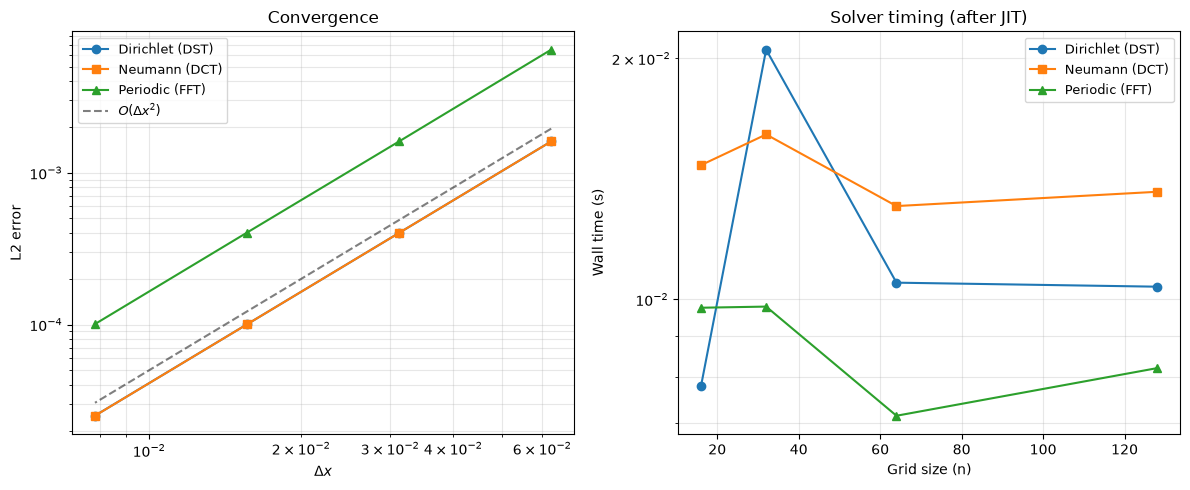

In [9]:
# Shapes: N_res = 4 resolutions

# Δx = 1 / N_Ωx,x
grid_spacings = [1.0 / resolution for resolution in resolutions]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# -- Convergence --
ax = axes[0]
ax.loglog(grid_spacings, dirichlet_errors, "o-", label="Dirichlet (DST)")
ax.loglog(grid_spacings, neumann_errors, "s-", label="Neumann (DCT)")
ax.loglog(grid_spacings, periodic_errors, "^-", label="Periodic (FFT)")
# reference O(Δx²) line
spacing_array = jnp.array(grid_spacings)  # → (N_res,)
reference_error = 0.5 * spacing_array**2  # → (N_res,)
ax.loglog(grid_spacings, reference_error, "k--", alpha=0.5, label=r"$O(\Delta x^2)$")
ax.set_xlabel(r"$\Delta x$")
ax.set_ylabel("L2 error")
ax.set_title("Convergence")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, which="both")

# -- Timing --
ax = axes[1]
ax.semilogy(resolutions, dirichlet_times, "o-", label="Dirichlet (DST)")
ax.semilogy(resolutions, neumann_times, "s-", label="Neumann (DCT)")
ax.semilogy(resolutions, periodic_times, "^-", label="Periodic (FFT)")
ax.set_xlabel("Grid size (n)")
ax.set_ylabel("Wall time (s)")
ax.set_title("Solver timing (after JIT)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, which="both")

plt.tight_layout()
plt.show()

## 5. A vortex pair

Inside a Navier–Stokes model this solver recovers the streamfunction from the vorticity at every step, with $u = \partial \psi / \partial y$ and $v = -\partial \psi / \partial x$ and the Poisson equation $\nabla^2 \psi = -\omega$, as in [Step 12](step12_cavity_flow.ipynb). Here we do it once, for a dipolar source and homogeneous Dirichlet boundaries. The closed $\psi$ contours are the streamlines of the vortex pair that the source implies.


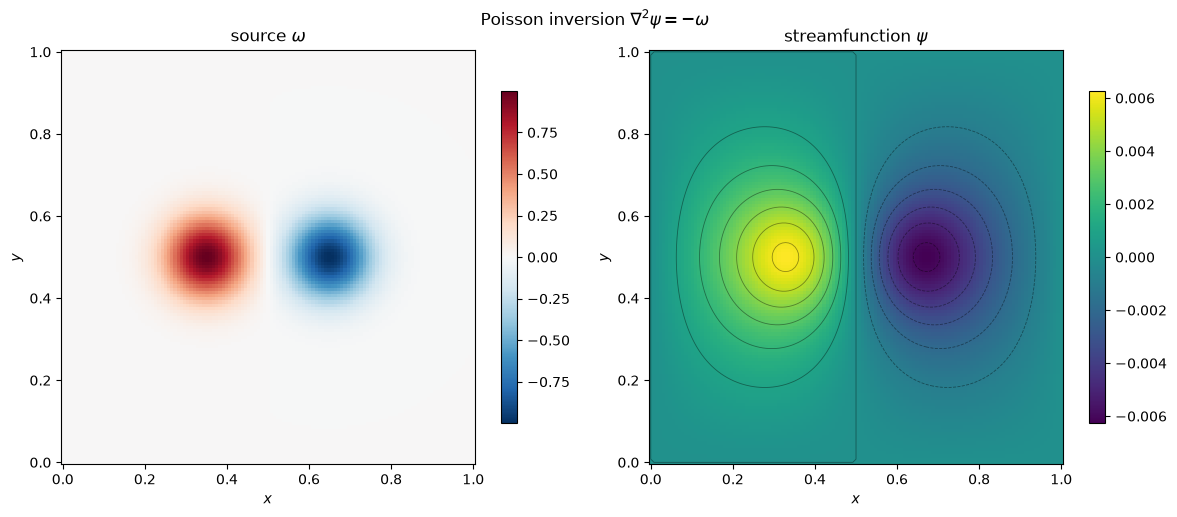

In [10]:
# Shapes: N_Ωx,x = N_Ωx,y = 128 interior cells;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# today (sesmax_core)
pair_solver = sxt.PoissonSolver2D.create(nx=128, ny=128, Lx=1.0, Ly=1.0, bc="dirichlet")

# xᵢ = i Δx
x_position = jnp.arange(pair_solver.grid.Nx) * pair_solver.grid.dx
# yⱼ = j Δy
y_position = jnp.arange(pair_solver.grid.Ny) * pair_solver.grid.dy
# (xᵢ, yⱼ) on every cell
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# r₊² = (x − 0.35)² + (y − 0.5)²
radius_positive = (x_grid - 0.35) ** 2 + (y_grid - 0.5) ** 2  # → G
# r₋² = (x − 0.65)² + (y − 0.5)²
radius_negative = (x_grid - 0.65) ** 2 + (y_grid - 0.5) ** 2  # → G
# ω = exp(−r₊² / 0.01) − exp(−r₋² / 0.01)
vortex_pair = jnp.exp(-radius_positive / 0.01) - jnp.exp(-radius_negative / 0.01)

# today (sesmax_core)
# ∇²ψ = −ω with ψ = 0 on the walls
streamfunction = pair_solver.solve(-vortex_pair)  # → G

# ψ on the nodes 0 … N_Ωx, walls included; the last row and column are ghosts
nodes = (slice(0, pair_solver.grid.Ny - 1), slice(0, pair_solver.grid.Nx - 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pcm = axes[0].pcolormesh(
    x_grid[nodes], y_grid[nodes], vortex_pair[nodes], cmap="RdBu_r"
)
axes[0].set_title(r"source $\omega$")
plt.colorbar(pcm, ax=axes[0], shrink=0.8)
pcm = axes[1].pcolormesh(
    x_grid[nodes], y_grid[nodes], streamfunction[nodes], cmap="viridis"
)
axes[1].contour(
    x_grid[nodes],
    y_grid[nodes],
    streamfunction[nodes],
    levels=12,
    colors="k",
    alpha=0.4,
    linewidths=0.6,
)
axes[1].set_title(r"streamfunction $\psi$")
plt.colorbar(pcm, ax=axes[1], shrink=0.8)
for ax in axes:
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")
plt.suptitle(r"Poisson inversion $\nabla^2 \psi = -\omega$")
plt.tight_layout()
plt.show()

## Summary

| BC type | Spectral method | `bc` argument |
| --- | --- | --- |
| Dirichlet | DST | `"dirichlet"` |
| Neumann | DCT | `"neumann"` |
| Periodic | FFT | `"periodic"` |

All three methods converge at $O(\Delta x^2)$ and run in $O(N \log N)$ time. The Poisson solver is the **key building block** for the pressure projection in Steps 12 and 13.

**Next:** [Step 11](step11_helmholtz_2d.ipynb) extends the Poisson solver with a Helmholtz (screening) term.